# Different Exact and Approximation Algorithms for the Travelling Salesperson Problem (TSP)

**Academic project - Computer Engineering / AI & ML**

This notebook is the main working environment of the project. It

1. explains the problem, its mathematical formulation and applications,
2. implements (via the reusable modules in `src/`) three **exact** algorithms - Brute Force, Held-Karp dynamic programming, Branch and Bound - and three **heuristic / approximation** algorithms - Nearest Neighbor, MST-preorder (2-approximation) and Christofides (1.5-approximation),
3. generates reproducible synthetic datasets,
4. validates every returned tour and re-computes every tour length independently,
5. measures execution time and memory, optimality gaps and scalability on identical inputs,
6. draws the cities and routes, and ends with a comparison and conclusion.

**How to run:** `Kernel -> Restart & Run All`. The full notebook takes roughly 2-4 minutes (the exponential algorithms are only run on small sizes). Set `QUICK = True` in the setup cell for a faster reduced run.

> Every number in this notebook is produced by running the code - nothing is typed in by hand.

## 1. Problem statement

A salesperson must visit each of *n* cities exactly once and return to the starting city. Given the travel cost between every pair of cities, find the **shortest possible closed tour**. The Travelling Salesperson Problem (TSP) is one of the most studied problems in combinatorial optimisation. Its decision version is **NP-complete**, so no polynomial-time exact algorithm is known (and none exists unless P = NP).

### Mathematical formulation

Let the cities be $V=\{0,1,\dots,n-1\}$ and let $d_{ij}\ge 0$ be the cost of going from $i$ to $j$ (matrix $D$). A tour is a permutation $\pi$ of $V$ with $\pi(0)=0$ (we fix city 0 as the start). Its length is

$$L(\pi)=\sum_{k=0}^{n-2} d_{\pi(k)\,\pi(k+1)} \;+\; d_{\pi(n-1)\,0}.$$

The goal is $\min_{\pi} L(\pi)$ over all $(n-1)!$ such permutations.

Equivalent integer program: binary variable $x_{ij}=1$ if the tour travels directly from $i$ to $j$:

$$\min \sum_{i\ne j} d_{ij}x_{ij}\quad\text{s.t.}\quad \sum_{j\ne i}x_{ij}=1,\;\; \sum_{i\ne j}x_{ij}=1\;\;\forall\,i,j,\qquad \sum_{i\in S}\sum_{j\notin S}x_{ij}\ge 1\;\;\forall\,\emptyset\ne S\subsetneq V.$$

The last family of constraints (sub-tour elimination) forbids tours that split into several disjoint cycles.

### Objectives of this project

* Implement and compare exact and approximation algorithms for the TSP.
* Verify correctness of every algorithm (valid tours, independently recomputed lengths, agreement of the exact algorithms).
* Measure running time and memory, and show how they scale with *n*.
* Quantify solution quality: optimality gap where the optimum is known, ratio to a valid lower bound otherwise.
* State clearly *when* the theoretical approximation guarantees hold.

### Assumptions

* **Symmetric TSP:** $d_{ij}=d_{ji}$ (the exact algorithms and Nearest Neighbor also accept asymmetric matrices; MST-preorder and Christofides require symmetry).
* $d_{ij}\ge 0$ and $d_{ii}=0$.
* **Metric TSP** (needed for the approximation guarantees): the triangle inequality $d_{ik}\le d_{ij}+d_{jk}$ holds. Euclidean distances always satisfy it.
* Complete graph: every city can be reached directly from every other.
* Tours are represented as closed lists, e.g. `[0, 3, 1, 2, 0]`.

### Real-world applications

Vehicle routing and delivery planning, school-bus and garbage-collection routes, drilling holes in circuit boards (PCB manufacturing), scheduling telescope observations, DNA fragment assembly / genome sequencing, warehouse order picking, robot arm path planning, and network design.

## 2. The algorithms and their complexity

| # | Algorithm | Kind | Time | Space | Quality guarantee |
|---|-----------|------|------|-------|-------------------|
| 1 | Brute Force | exact | $O(n!)$ | $O(n)$ | optimal |
| 2 | Held-Karp DP | exact | $O(2^n n^2)$ | $O(2^n n)$ | optimal |
| 3 | Branch and Bound | exact | $O(n!)$ worst case (usually much faster) | $O(n)$ | optimal |
| 4 | Nearest Neighbor | heuristic | $O(n^2)$ | $O(n)$ | **no universal constant factor**; for metric instances the worst-case ratio grows like $\log n$ (Rosenkrantz, Stearns & Lewis, 1977) |
| 5 | MST preorder | approximation | $O(n^2)$ | $O(n)$ | $\le 2\cdot$OPT for **symmetric metric** instances |
| 6 | Christofides | approximation | $O(n^3)$ | $O(n^2)$ | $\le 1.5\cdot$OPT for **symmetric metric** instances |

* **Brute force** enumerates all $(n-1)!$ tours (half of them for symmetric instances, since a tour and its reverse have the same length).
* **Held-Karp** stores, for every subset $S$ of cities and every end city $j\in S$, the cheapest path from city 0 through exactly $S$ ending at $j$, and builds larger subsets from smaller ones.
* **Branch and Bound** builds tours city by city and cuts a partial tour as soon as an *admissible lower bound* (cost so far + cheapest edge leaving the current city + the cheapest edge leaving every unvisited city) already reaches the best complete tour found so far. The bound never exceeds the true cost of any completion, so the optimum can never be discarded.
* **Nearest Neighbor** always walks to the closest unvisited city.
* **MST preorder:** build a minimum spanning tree, list the cities in depth-first preorder. Doubling the tree gives an Euler tour of length $2\,w(T)\le 2\,\mathrm{OPT}$; shortcutting repeated cities does not increase the length when the triangle inequality holds.
* **Christofides:** MST $T$, then a minimum-weight perfect matching $M$ on the odd-degree vertices of $T$, then an Eulerian circuit of $T\cup M$, then shortcutting. $w(T)\le \mathrm{OPT}$ and $w(M)\le \mathrm{OPT}/2$, hence length $\le 1.5\,\mathrm{OPT}$ (metric case).

## 3. Setup: imports, folders and settings

In [1]:
import inspect
import sys
import time
import unittest
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scipy

# --- locate the project root (works whether Jupyter was started in the project folder or in a sub-folder) ---
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import benchmarking as bm
from src import visualization as viz
from src.approximation_algorithms import christofides_tsp, mst_preorder_tsp, nearest_neighbor_tsp
from src.data_generator import generate_all_datasets, generate_cities
from src.distance_utils import (coords_from_dataframe, euclidean_distance_matrix, is_symmetric,
                                load_cities_csv, load_distance_matrix_csv, prim_mst,
                                satisfies_triangle_inequality, validate_distance_matrix)
from src.exact_algorithms import (branch_and_bound_tsp, brute_force_tsp, held_karp_tsp,
                                  one_tree_lower_bound)
from src.validation import is_valid_tour, recompute_tour_cost, verify_result

DATASETS = ROOT / "datasets"
RESULTS = ROOT / "results"
FIGURES = RESULTS / "figures"
ROUTES = FIGURES / "route_visualizations"

QUICK = False        # True = smaller experiments (about a minute); False = full experiments

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

print("Python      :", sys.version.split()[0])
print("NumPy       :", np.__version__, "| pandas:", pd.__version__, "| SciPy:", scipy.__version__)
print("Matplotlib  :", plt.matplotlib.__version__, "| NetworkX:", nx.__version__)
print("Project root:", ROOT)

Python      : 3.13.16
NumPy       : 2.5.3 | pandas: 3.0.5 | SciPy: 1.18.1
Matplotlib  : 3.11.2 | NetworkX: 3.6.1
Project root: /home/claude/TSP_Algorithm_Comparison_Project


## 4. Generate and load the datasets

`generate_all_datasets` writes three city-coordinate files (11, 50 and 200 cities, uniformly random in a 100 x 100 square, fixed seeds) and one custom distance-matrix file. Running it again always produces identical files. The format of every file is described in `datasets/dataset_README.md`.

In [2]:
generate_all_datasets(DATASETS)

cities = {k: load_cities_csv(DATASETS / f"cities_{k}.csv") for k in ("small", "medium", "large")}
coords = {k: coords_from_dataframe(v) for k, v in cities.items()}
print({k: len(v) for k, v in cities.items()})
print("\nFirst rows of cities_small.csv:")
display(cities["small"].head())

{'small': 11, 'medium': 50, 'large': 200}

First rows of cities_small.csv:


,city_id,x,y
0,0,77.4000,43.8900
1,1,85.8600,69.7400
2,2,9.4200,97.5600
3,3,76.1100,78.6100
4,4,12.8100,45.0400


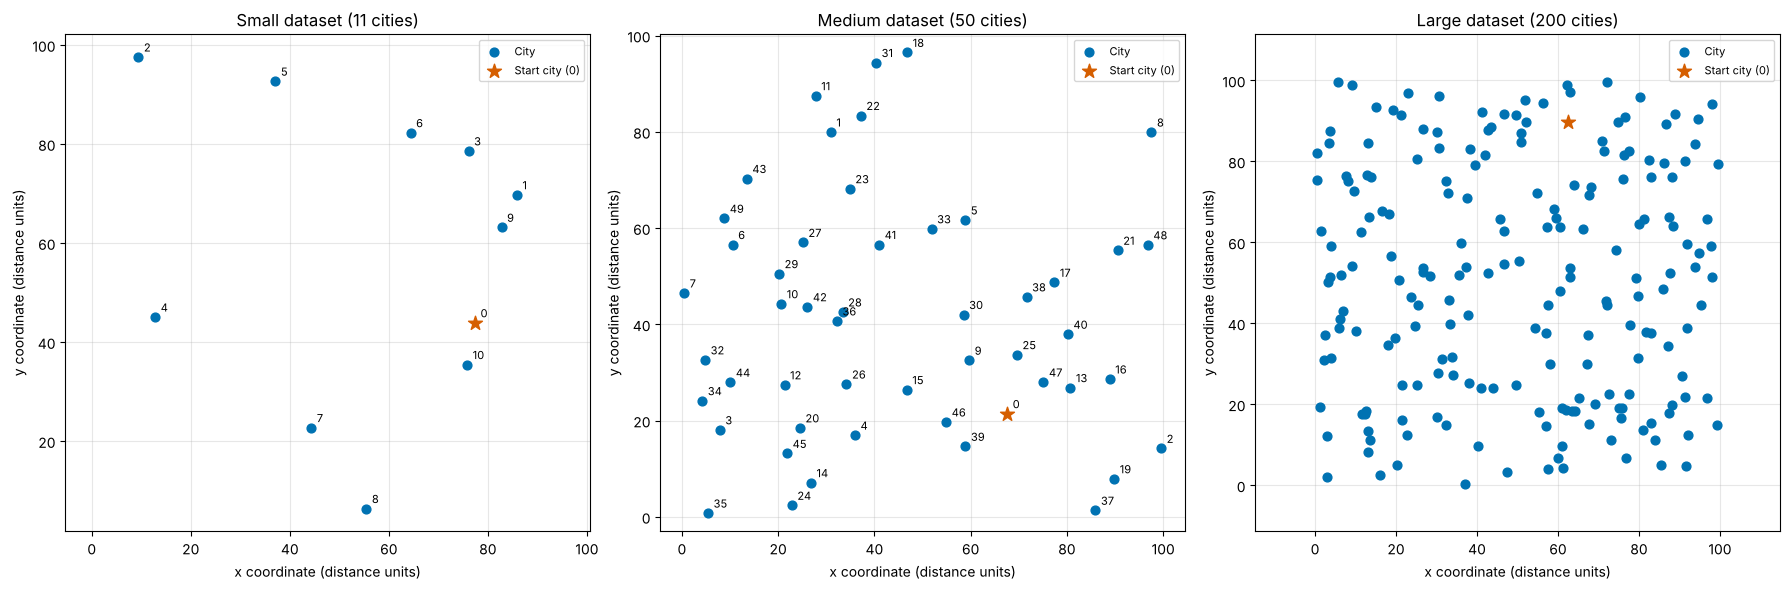

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, key in zip(axes, ("small", "medium", "large")):
    viz.plot_cities(coords[key], title=f"{key.capitalize()} dataset ({len(coords[key])} cities)", ax=ax,
                    annotate=(key != "large"))
fig.tight_layout()
fig.savefig(ROUTES / "city_datasets_overview.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Distance matrices and input validation

Every algorithm uses the **same** Euclidean distance matrix for a given dataset. Before use, each matrix is validated: square, finite, non-negative, zero diagonal, symmetric. We also test the triangle inequality, which decides whether the approximation guarantees apply.

In [4]:
matrices = {k: validate_distance_matrix(euclidean_distance_matrix(c)) for k, c in coords.items()}

checks = pd.DataFrame([{
    "dataset": k, "cities": len(D), "square": D.shape[0] == D.shape[1],
    "symmetric": is_symmetric(D), "zero diagonal": bool(np.all(np.diag(D) == 0)),
    "non-negative": bool(np.all(D >= 0)), "triangle inequality": satisfies_triangle_inequality(D),
    "min positive distance": D[D > 0].min(), "max distance": D.max()} for k, D in matrices.items()])
display(checks)

# What happens with a broken matrix?  validate_distance_matrix raises a clear error.
bad = np.array([[0, 1, -2], [1, 0, 3], [-2, 3, 0]], dtype=float)
try:
    validate_distance_matrix(bad)
except ValueError as err:
    print("Invalid matrix rejected ->", err)

,dataset,cities,square,symmetric,zero diagonal,non-negative,triangle inequality,min positive distance,max distance
0,small,11,True,True,True,True,True,7.2646,102.1444
1,medium,50,True,True,True,True,True,2.2027,121.4736
2,large,200,True,True,True,True,True,0.6021,132.2932


Invalid matrix rejected -> distance matrix contains negative distances


## 6. The algorithm implementations

All algorithms live in `src/` as separate, documented functions that take a distance matrix and return `(tour, cost)`. Here is the first paragraph of each docstring (open the files for the code and the complexity notes).

In [5]:
for func in (brute_force_tsp, held_karp_tsp, branch_and_bound_tsp,
             nearest_neighbor_tsp, mst_preorder_tsp, christofides_tsp):
    print(f"{func.__module__}.{func.__name__}{inspect.signature(func)}")
    print("   ", inspect.getdoc(func).split("\n\n")[0].replace("\n", " "))
    print()

src.exact_algorithms.brute_force_tsp(D, max_n: 'int' = 11)
    Try every possible tour and keep the cheapest.

src.exact_algorithms.held_karp_tsp(D, max_n: 'int' = 20)
    Held-Karp dynamic programming (Bellman 1962; Held & Karp 1962).

src.exact_algorithms.branch_and_bound_tsp(D, max_n: 'int' = 18, time_limit: 'float | None' = None, stats: 'dict | None' = None)
    Depth-first branch and bound.

src.approximation_algorithms.nearest_neighbor_tsp(D, start: 'int' = 0)
    Nearest Neighbor heuristic: always travel to the closest unvisited city.

src.approximation_algorithms.mst_preorder_tsp(D, start: 'int' = 0, warn_non_metric: 'bool' = True)
    MST + preorder walk (the classic 2-approximation).

src.approximation_algorithms.christofides_tsp(D, start: 'int' = 0, return_details: 'bool' = False, warn_non_metric: 'bool' = True)
    Christofides' algorithm.



### 6.1 Quick demonstration on the small dataset (11 cities)

Each algorithm is run once; the tour is checked with `validate_tour`-style logic (`is_valid_tour`), and its length is **recomputed independently** with plain Python loops (`recompute_tour_cost`) and compared with the length reported by the algorithm.

In [6]:
D_small = matrices["small"]
demo = []
for name, spec in bm.ALGORITHMS.items():
    tour, cost = bm._call(name, D_small)
    demo.append({"algorithm": name, "valid tour": is_valid_tour(tour, len(D_small)),
                 "starts/ends at 0": tour[0] == tour[-1] == 0,
                 "reported length": cost, "recomputed length": recompute_tour_cost(D_small, tour),
                 "lengths match": verify_result(D_small, tour, cost), "tour": tour})
demo = pd.DataFrame(demo)
display(demo)
assert demo["valid tour"].all() and demo["lengths match"].all()
print("All six tours are valid and their lengths were verified independently.")

,algorithm,valid tour,starts/ends at 0,reported length,recomputed length,lengths match,tour
0,Brute Force,True,True,265.1467,265.1467,True,"[0, 9, 1, 3, 6, 5, 2, 4, 7, 8, 10, 0]"
1,Held-Karp DP,True,True,265.1467,265.1467,True,"[0, 10, 8, 7, 4, 2, 5, 6, 3, 1, 9, 0]"
2,Branch and Bound,True,True,265.1467,265.1467,True,"[0, 10, 8, 7, 4, 2, 5, 6, 3, 1, 9, 0]"
3,Nearest Neighbor,True,True,281.6837,281.6837,True,"[0, 10, 9, 1, 3, 6, 5, 2, 4, 7, 8, 0]"
4,MST Preorder,True,True,368.7758,368.7758,True,"[0, 10, 7, 8, 4, 9, 1, 3, 6, 5, 2, 0]"
5,Christofides,True,True,265.1467,265.1467,True,"[0, 9, 1, 3, 6, 5, 2, 4, 7, 8, 10, 0]"


All six tours are valid and their lengths were verified independently.


## 7. Head-to-head comparison on the small dataset

`bm.one_instance` runs the algorithms on one identical matrix and records time (median of 3 runs, `time.perf_counter`), peak extra memory (`tracemalloc`, measured in a separate run so that tracing does not slow the timed runs), the optimal cost (from the exact algorithms), the **optimality gap** $100\,(L-L^*)/L^*$ and the ratio to a lower bound (the 1-tree bound, valid for symmetric TSP).

In [7]:
small_df = bm.one_instance(D_small, repeats=3, measure_memory=True)
small_tours = {r.algorithm: (r.tour, r.tour_cost) for r in small_df.itertuples()}
print("Do all exact algorithms agree on the optimum?", bool(small_df["exact_agree"].iloc[0]))
show = ["algorithm", "type", "tour_cost", "optimal_cost", "gap_pct", "time_s", "peak_memory_kb", "ratio_to_lower_bound"]
display(small_df[show])

Do all exact algorithms agree on the optimum? True


,algorithm,type,tour_cost,optimal_cost,gap_pct,time_s,peak_memory_kb,ratio_to_lower_bound
0,Brute Force,Exact,265.1467,265.1467,0.0000,1.6934,6.5479,1.0058
1,Held-Karp DP,Exact,265.1467,265.1467,0.0000,0.0154,107.1836,1.0058
2,Branch and Bound,Exact,265.1467,265.1467,0.0000,0.0042,5.9453,1.0058
3,Nearest Neighbor,Heuristic,281.6837,265.1467,6.2369,0.0001,2.5576,1.0686
4,MST Preorder,2-approximation (metric),368.7758,265.1467,39.0837,0.0002,4.8955,1.3990
5,Christofides,1.5-approximation (metric),265.1467,265.1467,0.0000,0.0008,34.6777,1.0058


### Route visualisation - every algorithm on the small dataset

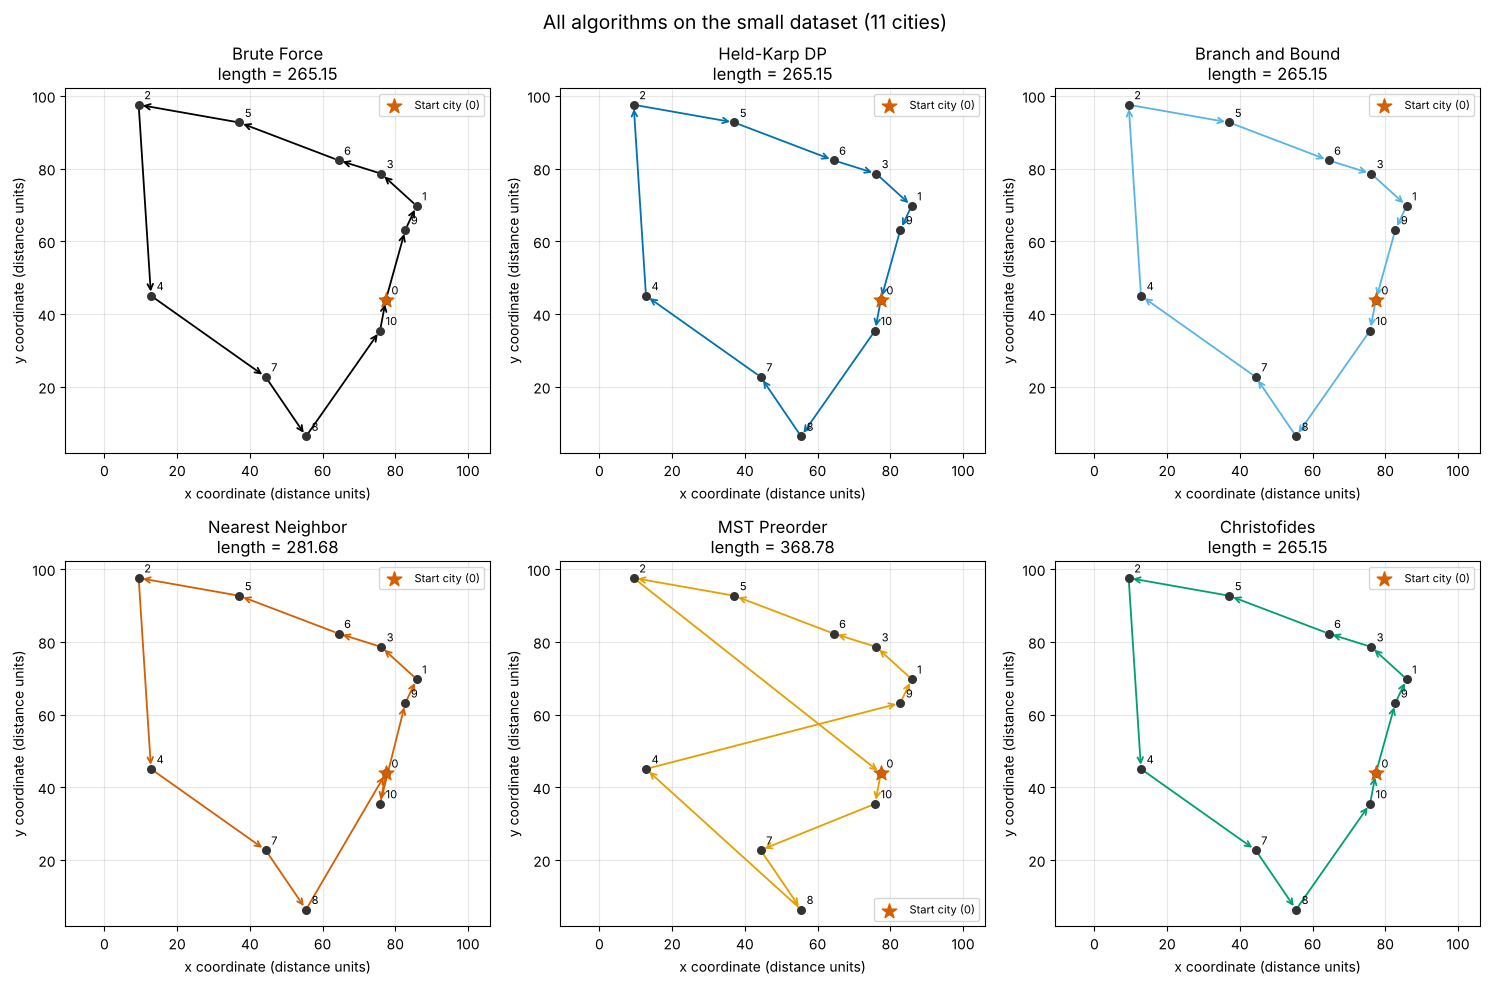

In [8]:
fig = viz.plot_tour_grid(coords["small"], small_tours, title="All algorithms on the small dataset (11 cities)",
                         save_path=ROUTES / "small_all_algorithms.png")
for name, (tour, cost) in small_tours.items():
    f = viz.plot_tour(coords["small"], tour, title=f"{name} - small dataset", cost=cost,
                      color=viz.ALGO_COLORS[name],
                      save_path=ROUTES / f"small_{name.lower().replace(' ', '_').replace('-', '_')}.png")
    plt.close(f)
plt.show()

### Route length and execution-time charts

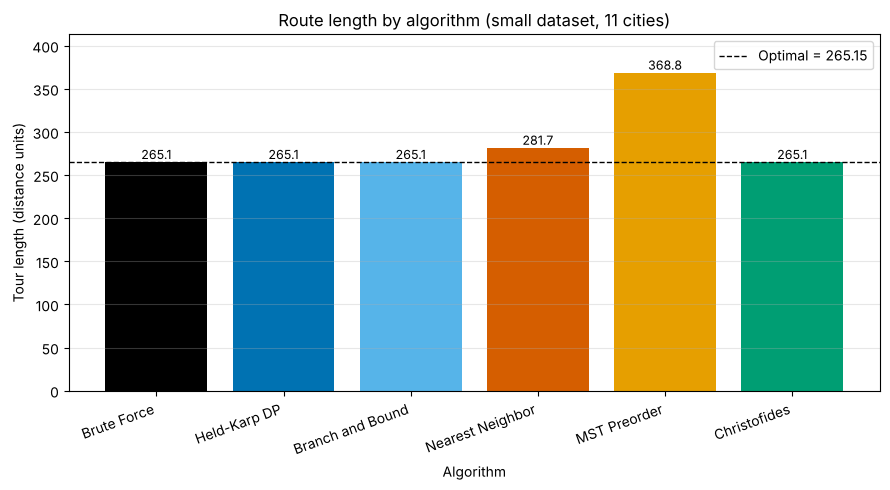

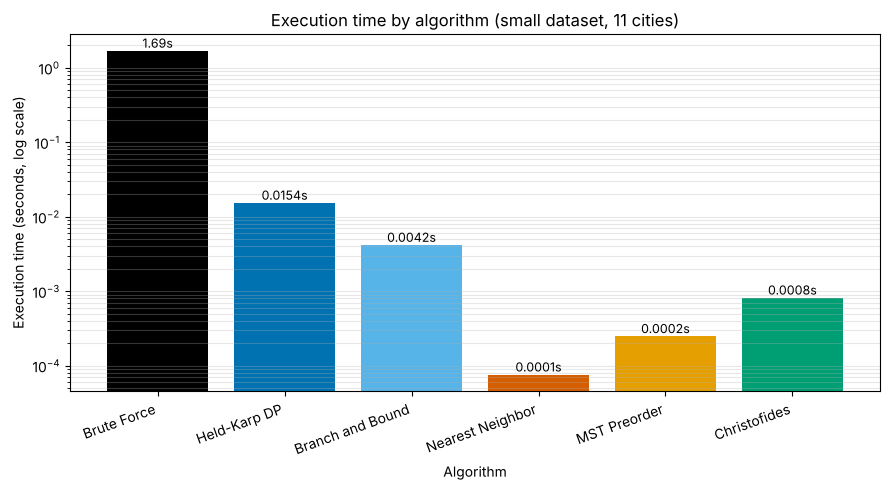

In [9]:
viz.plot_route_distance_comparison(small_df, title="Route length by algorithm (small dataset, 11 cities)",
                                   save_path=FIGURES / "route_distance_comparison.png")
plt.show()
viz.plot_execution_time_comparison(small_df, title="Execution time by algorithm (small dataset, 11 cities)",
                                   save_path=FIGURES / "execution_time_comparison.png")
plt.show()

### 7.1 Looking inside Christofides

`return_details=True` exposes the weights used in the proof. We can check the inequalities directly:
MST weight $\le$ OPT, matching weight $\le$ OPT/2 and tour length $\le$ MST + matching (metric case).

In [10]:
tour_c, cost_c, det = christofides_tsp(D_small, return_details=True)
opt_small = float(small_df["optimal_cost"].iloc[0])
proof = pd.DataFrame({
    "quantity": ["MST weight", "odd-degree vertices", "matching weight", "Euler walk length (MST + matching)",
                 "Christofides tour length", "optimal length"],
    "value": [det["mst_weight"], det["n_odd_vertices"], det["matching_weight"], det["euler_length"], cost_c, opt_small]})
display(proof)
print("MST <= OPT              :", det["mst_weight"] <= opt_small + 1e-9)
print("matching <= OPT / 2     :", det["matching_weight"] <= opt_small / 2 + 1e-9)
print("tour <= MST + matching  :", cost_c <= det["euler_length"] + 1e-9)
print("tour <= 1.5 * OPT       :", cost_c <= 1.5 * opt_small + 1e-9)

,quantity,value
0,MST weight,210.9796
1,odd-degree vertices,4.0000
2,matching weight,72.3942
3,Euler walk length (MST + matching),283.3737
4,Christofides tour length,265.1467
5,optimal length,265.1467


MST <= OPT              : True
matching <= OPT / 2     : True
tour <= MST + matching  : True
tour <= 1.5 * OPT       : True


## 8. Medium (50 cities) and large (200 cities) datasets

The exponential exact algorithms cannot run here (Held-Karp would need about $2^{49}\cdot 49$ table entries). The optimum is unknown, so quality is reported as **tour length / 1-tree lower bound**. Because the lower bound never exceeds the optimum, this ratio is an *upper bound* on the true ratio tour/OPT. (The bound is not tight, so the real ratio is lower.)

medium dataset - 50 cities, lower bound = 505.29


,algorithm,type,tour_cost,time_s,peak_memory_kb,ratio_to_lower_bound
0,Nearest Neighbor,Heuristic,698.7355,0.0004,3.4863,1.3828
1,MST Preorder,2-approximation (metric),786.0625,0.0019,62.9766,1.5557
2,Christofides,1.5-approximation (metric),653.1170,0.0175,273.9043,1.2925


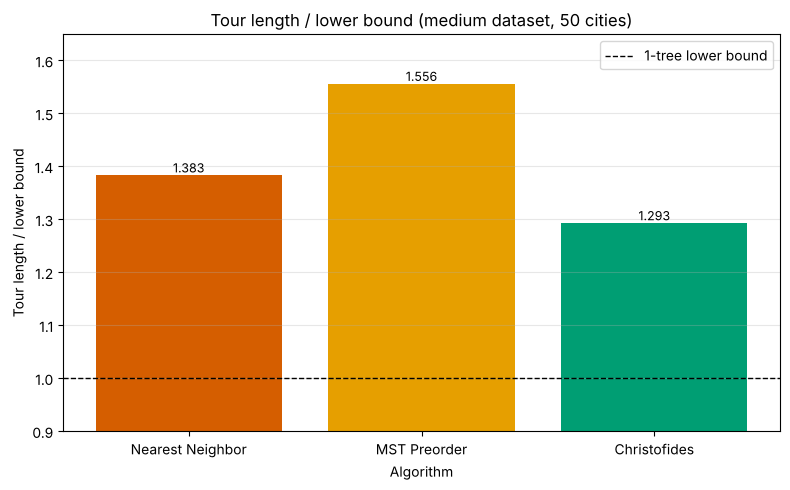

large dataset - 200 cities, lower bound = 986.86


,algorithm,type,tour_cost,time_s,peak_memory_kb,ratio_to_lower_bound
0,Nearest Neighbor,Heuristic,"1,344.7551",0.0009,39.3213,1.3627
1,MST Preorder,2-approximation (metric),"1,429.1721",0.0158,938.4648,1.4482
2,Christofides,1.5-approximation (metric),"1,238.0287",0.4489,"2,842.8145",1.2545


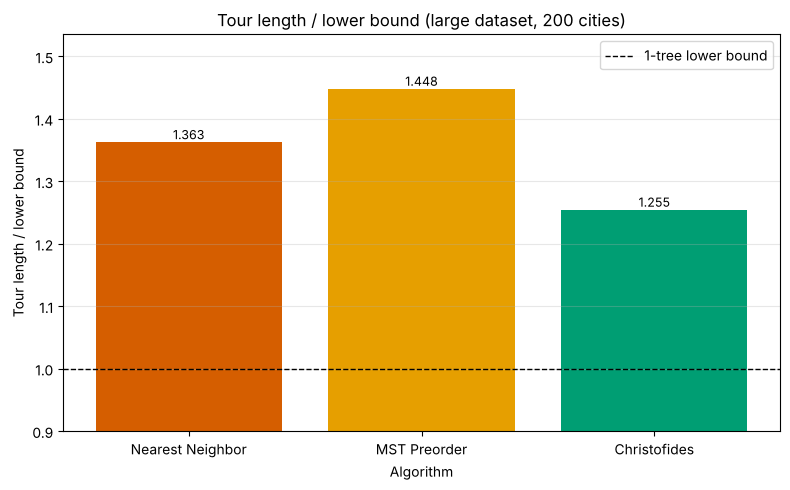

In [11]:
big_results = {}
for key in ("medium", "large"):
    df = bm.one_instance(matrices[key], algorithms=bm.APPROX_NAMES, repeats=3, measure_memory=True)
    big_results[key] = df
    print(f"{key} dataset - {len(matrices[key])} cities, lower bound = {df['lower_bound'].iloc[0]:.2f}")
    display(df[["algorithm", "type", "tour_cost", "time_s", "peak_memory_kb", "ratio_to_lower_bound"]])
    viz.plot_large_dataset_comparison(df, title=f"Tour length / lower bound ({key} dataset, {len(matrices[key])} cities)",
                                      save_path=FIGURES / f"ratio_to_lower_bound_{key}.png")
    plt.show()

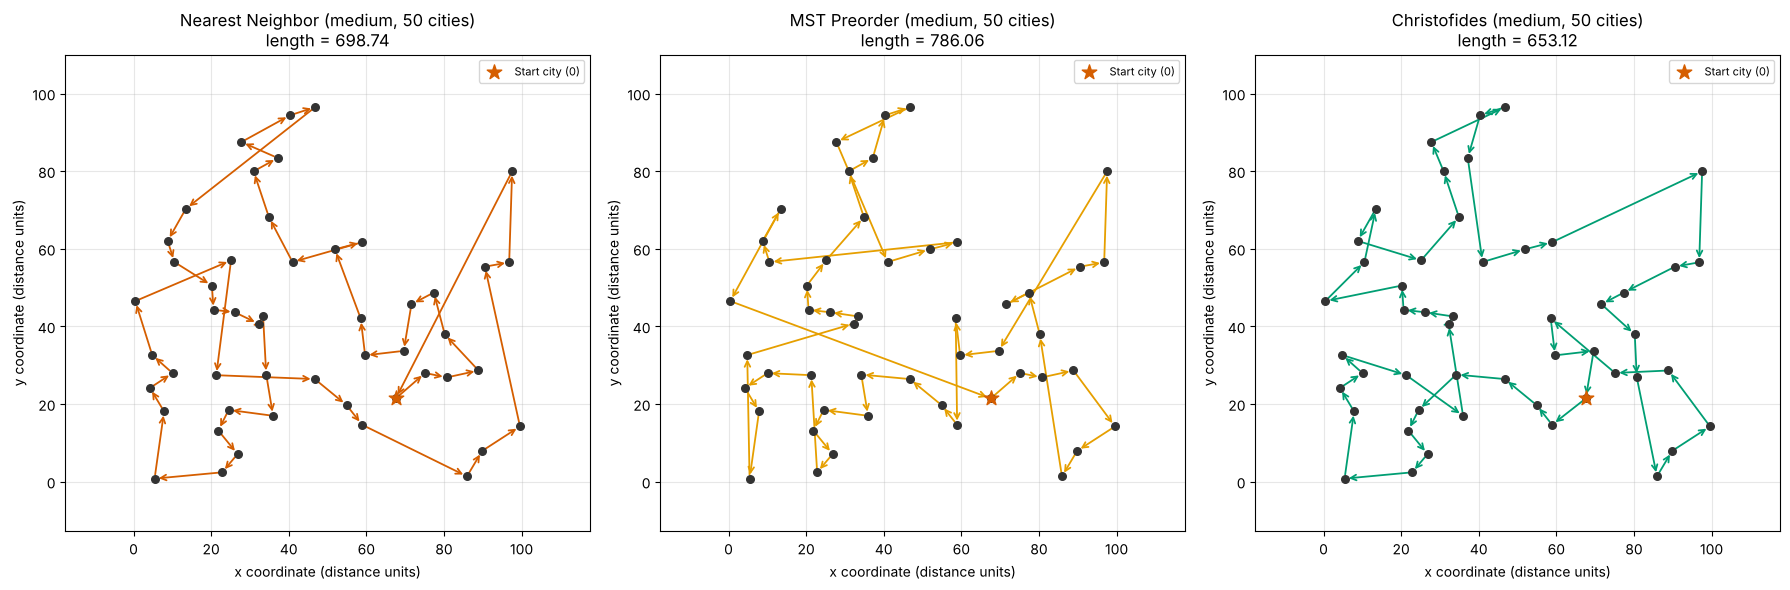

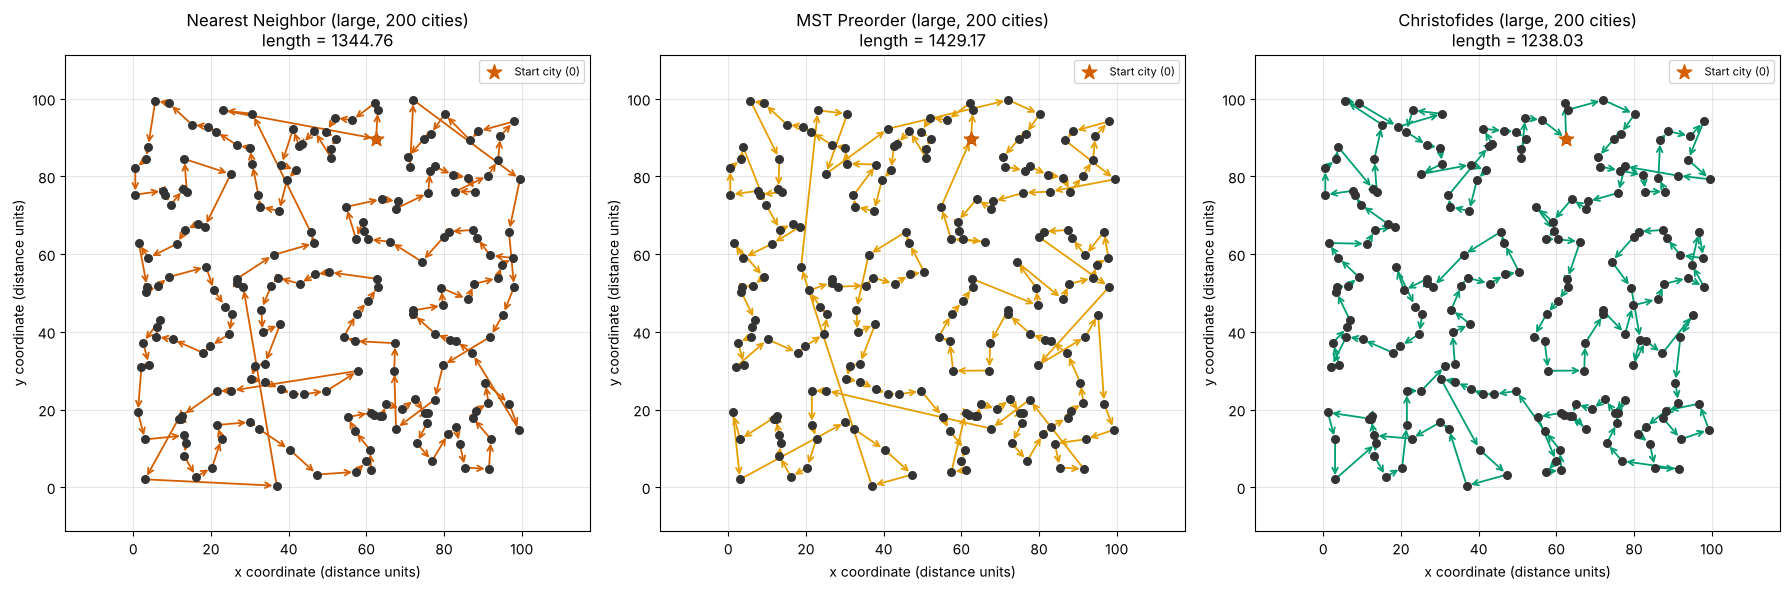

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, r in zip(axes, big_results["medium"].itertuples()):
    viz.plot_tour(coords["medium"], r.tour, title=f"{r.algorithm} (medium, 50 cities)", cost=r.tour_cost,
                  color=viz.ALGO_COLORS[r.algorithm], annotate=False, ax=ax)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, r in zip(axes, big_results["large"].itertuples()):
    viz.plot_tour(coords["large"], r.tour, title=f"{r.algorithm} (large, 200 cities)", cost=r.tour_cost,
                  color=viz.ALGO_COLORS[r.algorithm], annotate=False, ax=ax)
fig.tight_layout()
plt.show()

for key, df in big_results.items():          # also save each route as its own figure
    for r in df.itertuples():
        f = viz.plot_tour(coords[key], r.tour, title=f"{r.algorithm} - {key} dataset", cost=r.tour_cost,
                          color=viz.ALGO_COLORS[r.algorithm], annotate=False,
                          save_path=ROUTES / f"{key}_{r.algorithm.lower().replace(' ', '_')}.png")
        plt.close(f)

## 9. Optimality gaps on many random instances

A single instance can be misleading, so for each size $n\in\{6,8,10,12,14\}$ we generate 10 random instances (fixed seeds), compute the optimum with Held-Karp, cross-check it with Brute Force (n <= 10) and Branch and Bound (n <= 12), and measure the gap of the three polynomial-time algorithms. We also test, instance by instance, whether the guaranteed factors (2 for MST-preorder, 1.5 for Christofides) were respected. Nearest Neighbor has no such constant factor, so nothing is tested for it.

In [13]:
sizes = (6, 8, 10) if QUICK else (6, 8, 10, 12, 14)
seeds = range(1, 4) if QUICK else range(1, 11)
gaps = bm.run_optimality_gap_experiment(sizes=sizes, seeds=seeds)
gaps.to_csv(RESULTS / "optimality_gap_results.csv", index=False)

print("instances:", gaps[["n", "seed"]].drop_duplicates().shape[0])
print("all exact algorithms agreed on every instance:", bool(gaps["exact_methods_agree"].all()))
print("all tours valid                              :", bool(gaps["valid_tour"].all()))

approx = gaps[gaps["algorithm"].isin(bm.APPROX_NAMES)]
summary = approx.groupby("algorithm")["gap_pct"].agg(["mean", "median", "max"]).rename(
    columns={"mean": "mean gap %", "median": "median gap %", "max": "worst gap %"})
display(summary)
display(approx.pivot_table(index="n", columns="algorithm", values="gap_pct", aggfunc="mean").rename_axis(columns="mean gap % by n"))

g = approx.dropna(subset=["within_guarantee"])
print(f"\nGuarantee checks: {len(g)}; violated: {int((~g['within_guarantee'].astype(bool)).sum())}")
display(g.groupby("algorithm")["ratio_to_optimal"].max().to_frame("largest observed tour/OPT ratio"))

instances: 50
all exact algorithms agreed on every instance: True
all tours valid                              : True


,mean gap %,median gap %,worst gap %
algorithm,,,
Christofides,5.1655,4.5331,20.5805
MST Preorder,15.1328,16.0170,32.0629
Nearest Neighbor,8.1710,5.9333,47.4550


mean gap % by n,Christofides,MST Preorder,Nearest Neighbor
n,,,
6,1.9630,4.3319,2.1842
8,1.9241,16.3852,5.4859
10,7.2310,9.3574,6.3925
12,7.9413,22.1476,13.0233
14,6.7681,23.4418,13.7692



Guarantee checks: 100; violated: 0


,largest observed tour/OPT ratio
algorithm,
Christofides,1.2058
MST Preorder,1.3206


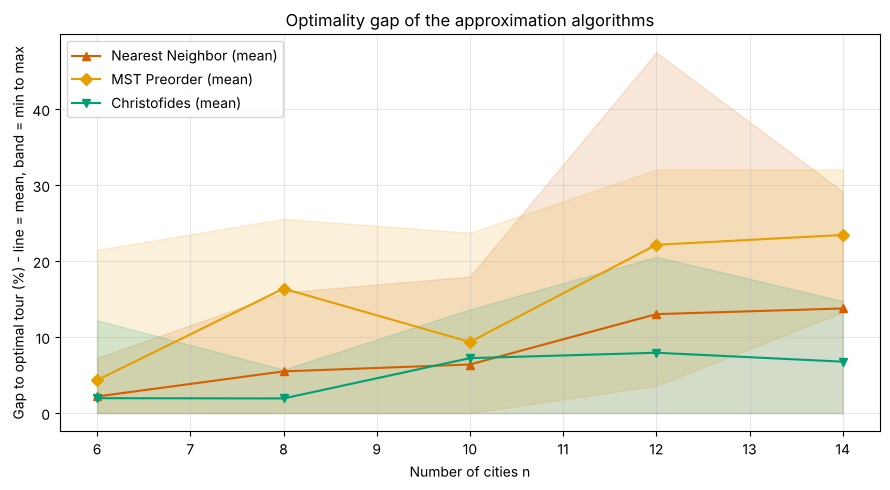

In [14]:
viz.plot_gap_by_size(gaps, save_path=FIGURES / "optimality_gap_by_size.png")
plt.show()

## 10. Scalability: how running time and memory grow with *n*

We take the first *n* cities of the large dataset for increasing *n* (so all algorithms see identical, nested instances) and run every algorithm that is within its sensible size limit. Limits used in the benchmark are set from measured running times: **Brute Force n <= 11**, **Held-Karp n <= 18**, **Branch and Bound n <= 20**; the three polynomial-time algorithms run up to n = 200. The functions refuse larger inputs with a `ValueError` unless the limit is deliberately raised. Memory is measured only for runs shorter than `MEMORY_TIME_CUTOFF` seconds because `tracemalloc` slows code down considerably (missing values in the table mean "not measured").

In [15]:
print("benchmark size limits:", {k: v["max_n"] for k, v in bm.ALGORITHMS.items()})
scal_sizes = [5, 8, 10, 11, 12, 14, 16, 18, 20, 30, 50, 100] if QUICK else None
scal = bm.run_scalability_experiment(coords["large"], sizes=scal_sizes, repeats=3)
scal.to_csv(RESULTS / "scalability_results.csv", index=False)
print("rows:", len(scal), "| all tours valid:", bool(scal.loc[scal["status"] == "ok", "valid_tour"].all()))
display(scal.pivot(index="n", columns="algorithm", values="time_s").rename_axis(columns="execution time (s)"))

benchmark size limits: {'Brute Force': 11, 'Held-Karp DP': 18, 'Branch and Bound': 20, 'Nearest Neighbor': None, 'MST Preorder': None, 'Christofides': None}
rows: 99 | all tours valid: True


execution time (s),Branch and Bound,Brute Force,Christofides,Held-Karp DP,MST Preorder,Nearest Neighbor
n,,,,,,
5,0.0001,0.0001,0.0005,0.0003,0.0002,0.0001
6,0.0002,0.0001,0.0005,0.0005,0.0002,0.0001
7,0.0003,0.0003,0.0007,0.0011,0.0002,0.0001
8,0.0008,0.0018,0.0008,0.0020,0.0002,0.0001
9,0.0018,0.0149,0.0010,0.0039,0.0002,0.0001
10,0.0041,0.1494,0.0012,0.0073,0.0002,0.0001
11,0.0156,1.6438,0.0014,0.0157,0.0003,0.0002
12,0.0247,NaN,0.0012,0.0304,0.0004,0.0001
13,0.0391,NaN,0.0010,0.0611,0.0006,0.0001


In [16]:
display(scal.pivot(index="n", columns="algorithm", values="peak_memory_kb").rename_axis(columns="peak extra memory (KiB)"))
display(scal.pivot(index="n", columns="algorithm", values="ratio_to_lower_bound").rename_axis(columns="tour / 1-tree lower bound"))

peak extra memory (KiB),Branch and Bound,Brute Force,Christofides,Held-Karp DP,MST Preorder,Nearest Neighbor
n,,,,,,
5,2.9502,2.9150,20.0176,5.6797,2.6074,2.3525
6,2.9746,3.2344,21.9785,6.8086,2.9062,2.3691
7,3.1445,3.5752,26.8066,9.2773,3.1377,2.3857
8,3.7539,4.1094,28.9590,14.6055,3.5039,2.4023
9,4.1523,4.6650,36.1582,26.2305,3.9189,2.4189
10,5.1562,5.2422,46.3965,51.7148,4.3828,2.4980
11,5.8047,6.4619,48.7754,107.1836,4.8955,2.5146
12,7.6016,NaN,49.1035,227.7422,5.4570,2.5312
13,8.7461,NaN,43.0957,488.2617,6.0674,2.5479


tour / 1-tree lower bound,Branch and Bound,Brute Force,Christofides,Held-Karp DP,MST Preorder,Nearest Neighbor
n,,,,,,
5,1.1413,1.1413,1.1413,1.1413,1.2003,1.2003
6,1.0000,1.0000,1.0000,1.0000,1.1991,1.0000
7,1.0000,1.0000,1.1144,1.0000,1.1150,1.0000
8,1.0501,1.0501,1.2025,1.0501,1.2332,1.1256
9,1.0747,1.0747,1.2493,1.0747,1.2088,1.1127
10,1.0779,1.0779,1.2471,1.0779,1.2078,1.1148
11,1.1116,1.1116,1.2595,1.1116,1.2400,1.1574
12,1.0791,NaN,1.2015,1.0791,1.2928,1.1044
13,1.0729,NaN,1.1816,1.0729,1.1891,1.0820


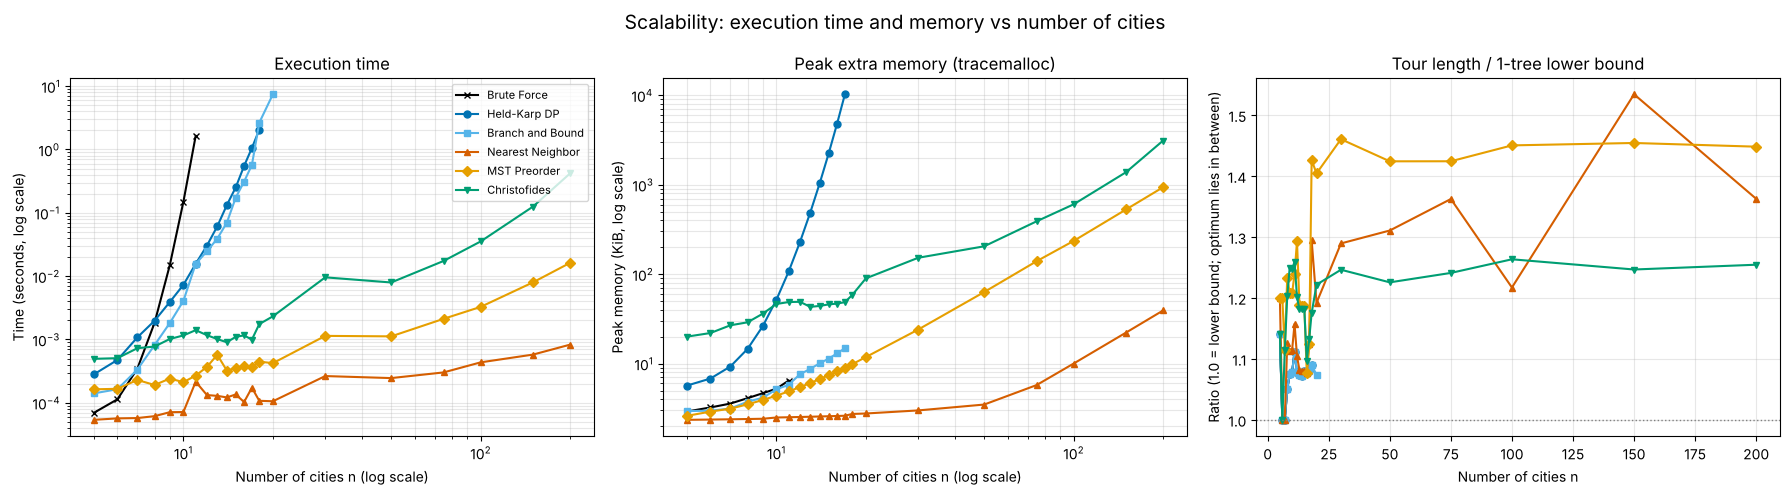

In [17]:
viz.plot_scalability(scal, save_path=FIGURES / "scalability_comparison.png")
plt.show()

### 10.1 Why is Branch and Bound faster than Brute Force?

Branch and Bound explores far fewer partial tours because the lower bound cuts hopeless branches. The next table counts how many search-tree nodes it expanded compared with the $(n-1)!/2$ complete tours that brute force would have to look at (for the same instances).

In [18]:
import math
rows = []
for n in range(6, 17):
    D = euclidean_distance_matrix(coords["large"][:n])
    stats = {}
    t0 = time.perf_counter()
    branch_and_bound_tsp(D, stats=stats)
    rows.append({"n": n, "B&B nodes expanded": stats["nodes_expanded"], "B&B nodes pruned": stats["nodes_pruned"],
                 "brute-force tours (n-1)!/2": math.factorial(n - 1) // 2, "B&B time (s)": time.perf_counter() - t0})
bb_stats = pd.DataFrame(rows).set_index("n")
bb_stats.to_csv(RESULTS / "branch_and_bound_node_counts.csv")
display(bb_stats)

,B&B nodes expanded,B&B nodes pruned,brute-force tours (n-1)!/2,B&B time (s)
n,,,,
6,32,23,60,0.0003
7,71,54,360,0.0003
8,278,206,2520,0.0008
9,548,428,20160,0.0016
10,1329,1072,181440,0.0040
11,4901,4015,1814400,0.0155
12,6707,5618,19958400,0.0241
13,9716,8248,239500800,0.0386
14,14872,12864,3113510400,0.0685


## 11. Custom distance matrix and special cases

The sample matrix `datasets/sample_distance_matrix.csv` contains Manhattan (street-grid) distances between six named places - symmetric and metric, but **not** Euclidean. All six algorithms accept it.

In [19]:
D_custom, labels = load_distance_matrix_csv(DATASETS / "sample_distance_matrix.csv")
D_custom = validate_distance_matrix(D_custom)
display(pd.DataFrame(D_custom, index=labels, columns=labels))

rows = []
for name in bm.ALGORITHMS:
    tour, cost = bm._call(name, D_custom)
    rows.append({"algorithm": name, "length (km)": cost, "route": " -> ".join(labels[i] for i in tour)})
display(pd.DataFrame(rows))

,Depot,North,East,South,West,Market
Depot,0.0000,9.0000,11.0000,8.0000,7.0000,14.0000
North,9.0000,0.0000,10.0000,13.0000,12.0000,5.0000
East,11.0000,10.0000,0.0000,11.0000,14.0000,7.0000
South,8.0000,13.0000,11.0000,0.0000,15.0000,14.0000
West,7.0000,12.0000,14.0000,15.0000,0.0000,17.0000
Market,14.0000,5.0000,7.0000,14.0000,17.0000,0.0000


,algorithm,length (km),route
0,Brute Force,50.0000,Depot -> South -> East -> Market -> North -> West -> Depot
1,Held-Karp DP,50.0000,Depot -> West -> North -> Market -> East -> South -> Depot
2,Branch and Bound,50.0000,Depot -> West -> North -> Market -> East -> South -> Depot
3,Nearest Neighbor,50.0000,Depot -> West -> North -> Market -> East -> South -> Depot
4,MST Preorder,58.0000,Depot -> West -> South -> North -> Market -> East -> Depot
5,Christofides,54.0000,Depot -> North -> Market -> East -> South -> West -> Depot


**Asymmetric matrices.** The exact algorithms and Nearest Neighbor follow `D[i][j]` as given (direction matters). MST-preorder and Christofides are defined for symmetric costs, so they reject asymmetric input with a clear error rather than silently returning a meaningless answer. **Non-metric matrices.** If the triangle inequality is violated, the two approximation algorithms still return valid tours, but they issue a warning because the 2x / 1.5x guarantees no longer apply.

In [20]:
asym = np.array([[0, 1, 9, 9], [9, 0, 1, 9], [9, 9, 0, 1], [1, 9, 9, 0]], dtype=float)   # cheap one-way cycle 0->1->2->3->0
print("asymmetric matrix, exact algorithms:")
for f in (brute_force_tsp, held_karp_tsp, branch_and_bound_tsp):
    print(f"  {f.__name__:<22}", f(asym))
print("  nearest_neighbor_tsp  ", nearest_neighbor_tsp(asym))
for f in (mst_preorder_tsp, christofides_tsp):
    try:
        f(asym)
    except ValueError as err:
        print(f"  {f.__name__} -> ValueError: {err}")

non_metric = np.array([[0, 1, 10, 4], [1, 0, 1, 9], [10, 1, 0, 1], [4, 9, 1, 0]], dtype=float)
print("\nnon-metric symmetric matrix:", satisfies_triangle_inequality(non_metric))
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    print("  christofides ->", christofides_tsp(non_metric))
print("  warning issued:", caught[0].message if caught else None)

asymmetric matrix, exact algorithms:
  brute_force_tsp        ([0, 1, 2, 3, 0], 4.0)
  held_karp_tsp          ([0, 1, 2, 3, 0], 4.0)
  branch_and_bound_tsp   ([0, 1, 2, 3, 0], 4.0)
  nearest_neighbor_tsp   ([0, 1, 2, 3, 0], 4.0)
  mst_preorder_tsp -> ValueError: distance matrix must be symmetric for this algorithm
  christofides_tsp -> ValueError: distance matrix must be symmetric for this algorithm

non-metric symmetric matrix: False
  christofides -> ([0, 3, 2, 1, 0], 7.0)
  warning issued: christofides_tsp: the distance matrix violates the triangle inequality, so the approximation guarantee does not apply (the returned tour is still valid).


## 12. Unit tests

The same test-suite that is shipped in `tests/` is executed here (`python -m unittest discover -s tests` from a terminal works as well). It checks tour validity, independent cost recomputation, agreement of the three exact algorithms on many instances (including asymmetric ones), admissibility of the Branch-and-Bound bound, the 2x and 1.5x guarantees on metric instances, edge cases (1, 2, 3 cities, duplicate cities), invalid matrices, size limits, and cross-checks of the MST and distance matrix against SciPy.

In [21]:
suite = unittest.defaultTestLoader.discover(str(ROOT / "tests"))
result = unittest.TextTestRunner(verbosity=1, stream=sys.stdout).run(suite)
print(f"\ntests run: {result.testsRun} | failures: {len(result.failures)} | errors: {len(result.errors)} | skipped: {len(result.skipped)}")
assert result.wasSuccessful()

..................................................................
----------------------------------------------------------------------
Ran 66 tests in 1.670s

OK

tests run: 66 | failures: 0 | errors: 0 | skipped: 0


## 13. Results summary and observations

The cell below recomputes the key findings from the result tables, so the numbers shown always correspond to the run that produced them.

In [22]:
sm = small_df.set_index("algorithm")
print(f"Small dataset (11 cities): optimal tour length = {sm['optimal_cost'].iloc[0]:.2f}")
for name in bm.APPROX_NAMES:
    print(f"  {name:<17} length {sm.loc[name, 'tour_cost']:8.2f}   gap {sm.loc[name, 'gap_pct']:6.2f} %")
print(f"  Brute Force took {sm.loc['Brute Force', 'time_s']:.3f} s, Held-Karp {sm.loc['Held-Karp DP', 'time_s']:.4f} s, "
      f"Branch and Bound {sm.loc['Branch and Bound', 'time_s']:.4f} s")

print("\nMean / worst optimality gap over all random instances (n = %s):" % list(sizes))
display(summary)

for key in ("medium", "large"):
    d = big_results[key].set_index("algorithm")["ratio_to_lower_bound"]
    best = d.idxmin()
    print(f"{key:<6} dataset: tour/lower-bound ratios " + ", ".join(f"{a} {v:.3f}" for a, v in d.items()) + f"  -> best: {best}")

ok = scal[scal["status"] == "ok"]
largest = ok.groupby("algorithm")["n"].max()
print("\nLargest n run per algorithm:", largest.to_dict())
t200 = ok[ok["n"] == ok["n"].max()].set_index("algorithm")["time_s"]
print(f"At n = {ok['n'].max()}: " + ", ".join(f"{a} {v:.4f}s" for a, v in t200.items()))

Small dataset (11 cities): optimal tour length = 265.15
  Nearest Neighbor  length   281.68   gap   6.24 %
  MST Preorder      length   368.78   gap  39.08 %
  Christofides      length   265.15   gap   0.00 %
  Brute Force took 1.693 s, Held-Karp 0.0154 s, Branch and Bound 0.0042 s

Mean / worst optimality gap over all random instances (n = [6, 8, 10, 12, 14]):


,mean gap %,median gap %,worst gap %
algorithm,,,
Christofides,5.1655,4.5331,20.5805
MST Preorder,15.1328,16.0170,32.0629
Nearest Neighbor,8.1710,5.9333,47.4550


medium dataset: tour/lower-bound ratios Nearest Neighbor 1.383, MST Preorder 1.556, Christofides 1.293  -> best: Christofides
large  dataset: tour/lower-bound ratios Nearest Neighbor 1.363, MST Preorder 1.448, Christofides 1.255  -> best: Christofides

Largest n run per algorithm: {'Branch and Bound': 20, 'Brute Force': 11, 'Christofides': 200, 'Held-Karp DP': 18, 'MST Preorder': 200, 'Nearest Neighbor': 200}
At n = 200: Nearest Neighbor 0.0008s, MST Preorder 0.0163s, Christofides 0.4207s


### Observations (read together with the tables and figures above)

* **Exactness.** Brute Force, Held-Karp and Branch and Bound returned the same optimal length on every instance on which they were all run, and every returned tour was valid with an independently recomputed length equal to the reported one.
* **Time growth.** Brute Force explodes factorially: it is the first to become impractical (n = 11 is already the slowest run by a wide margin, while Held-Karp and Branch and Bound take a small fraction of the time). Held-Karp grows exponentially ($2^n n^2$ time) and its table memory also grows exponentially ($2^n n$), which is what finally limits it. Branch and Bound is often the fastest exact method, but its running time depends strongly on the instance - its worst case is still factorial - so it can not be ranked above Held-Karp in general. In our runs the two were of the same order of magnitude for n around 16-18.
* **Heuristics are almost free.** Nearest Neighbor and MST-preorder need microseconds-milliseconds even for 200 cities; Christofides is the most expensive of the three (its matching step is cubic) but still finishes 200 cities in well under a second.
* **Quality.** Averaged over the random instances, Christofides had the smallest gap, Nearest Neighbor was in the middle and MST-preorder was the worst. On the medium and large datasets Christofides also gave the shortest tours. This ordering is what we measured on *these* random uniform instances; it is not a theorem. Nearest Neighbor has no constant worst-case guarantee, so its good average behaviour here must not be read as a guarantee.
* **Guarantees were respected.** MST-preorder stayed below 2x and Christofides below 1.5x the optimum on all checked instances, as the theory predicts for metric instances. The *observed* ratios are much smaller than the worst-case factors: guarantees describe the worst case, not typical behaviour.
* **Trade-off.** Use exact methods when n is small (up to about 15-20 cities) and the optimum is required; use Christofides (or Nearest Neighbor when speed is crucial) for larger instances; in practice, local-search methods such as 2-opt / Lin-Kernighan (not part of this project) improve such tours further.

## 14. Conclusion

All six algorithms were implemented, validated and benchmarked on identical Euclidean instances. Exact algorithms guarantee optimal tours but only scale to roughly 10-20 cities because the problem is NP-hard; Held-Karp trades time for exponential memory and Branch and Bound relies on pruning that works well on average but not in the worst case. Approximation algorithms scale to hundreds of cities in well under a second, and their solution quality is bounded (2x for MST-preorder, 1.5x for Christofides) when the instance is symmetric and satisfies the triangle inequality. In our experiments Christofides gave the best quality/time compromise among the polynomial-time methods, Nearest Neighbor the fastest results with moderate quality loss, and MST-preorder the weakest tours.

### Limitations
* All instances are random uniform Euclidean points; other structures (clustered cities, real road networks, asymmetric costs) may behave differently.
* Timings come from a single machine and depend on the CPU and on Python/NumPy overheads; compare the *growth*, not the absolute seconds. Memory is the peak traced by `tracemalloc` (Python and NumPy allocations), not the process's total memory.
* Branch and Bound times are instance dependent; only one nested family of instances is used for the scalability table.
* No local-search improvement (2-opt, Or-opt, Lin-Kernighan) or integer-programming solver is included.